# MovieLens ile Graf Tabanlı Film Öneri Sistemi
**Araştırma sorusu.** Bir kullanıcının daha önce beğendiği filmlerden yola çıkarak sonradan beğeneceği filmleri ona önerebilir miyiz? Bu öneriler popüler filmleri önermekten daha isabetli mi?

**Veri kaynağı.** Bu projede GroupLens’in [MovieLens Latest Small](https://grouplens.org/datasets/movielens/latest/) veri setinin 26 Eylül 2018’de oluşturulan Eylül 2018 sürümü (`ml-latest-small.zip`) kullanılmıştır.

In [23]:
from pathlib import Path
from hashlib import sha256
from time import perf_counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, diags

data_dir = Path(".") if Path("ratings.csv").is_file() else Path("ml-latest-small")
ratings_file = data_dir / "ratings.csv"
ratings = pd.read_csv(ratings_file)
movies = pd.read_csv(data_dir / "movies.csv")
titles = movies.set_index("movieId")["title"]

assert ratings[["userId", "movieId", "rating", "timestamp"]].notna().all().all()
assert not ratings.duplicated(["userId", "movieId"]).any()
assert titles.index.is_unique
assert ratings["movieId"].isin(titles.index).all()
assert ratings["rating"].between(0.5, 5).all()

print("ratings.csv SHA-256:", sha256(ratings_file.read_bytes()).hexdigest())
print("Puanlama:", len(ratings), "| Kullanıcı:", ratings.userId.nunique(),
      "| Katalogdaki film:", len(movies))
display(ratings.head())
display(movies.head())

ratings.csv SHA-256: aa289ca83157595d0df6aea1be6a4ded676ddc4385472e8313a8ed9805352646
Puanlama: 100836 | Kullanıcı: 610 | Katalogdaki film: 9742


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## Puanlamaları zamana göre ayırma

Puanlamaları tarihe göre sıraladık. En eski puanlamalardan başlayarak verinin yaklaşık %80’ini eğitim için geri kalanını ise önerileri test etmek için kullandık.

Her kullanıcı için eğitim verisinde yer alan ve kullanıcının eğitim döneminde puanlamadığı filmler arasından 10 film önerdik. Test döneminde kullanıcının 5 üzerinden 4 veya daha yüksek puan verdiği filmleri beğenilmiş saydık. Öneri yöntemlerini karşılaştırmak için bu filmlerden kaçının öneri listelerine girdiğini ölçtük.

Test döneminde 116 kullanıcı film puanladı. Bu kullanıcıların 88’inin eğitim döneminde puanlama geçmişi yoktu. Dört yöntemi, eğitimde puanlama geçmişi olan ve testte öneri adaylarından en az birine 4 veya üzeri puan veren 28 kullanıcı üzerinde karşılaştırdık.

Test dönemindeki 9.325 beğeninin 665’i değerlendirmeye dahil edildi. Dışarıda kalan beğenilerin 8.360’ı eğitimde puanlama geçmişi olmayan kullanıcılara aitti. Diğer 300 beğeni ise eğitimde puanlama geçmişi olan kullanıcıların, eğitim döneminde hiç puanlanmamış filmlere verdiği puanlardan oluşuyordu. Bu nedenle performans sonuçları, eğitimde görülen ve testte en az bir aday filmi beğenen 28 kullanıcıyı kapsıyor.

In [24]:
LIKE = 4.0
K = 10
cutoff = ratings.timestamp.sort_values().iloc[int(0.8 * (len(ratings) - 1))]
train = ratings.loc[ratings.timestamp <= cutoff].copy()
test = ratings.loc[ratings.timestamp > cutoff].copy()
assert len(train) and len(test)
assert train.timestamp.max() < test.timestamp.min()

user_ids = np.sort(train.userId.unique())
movie_ids = np.sort(train.movieId.unique())
user_index = {uid: i for i, uid in enumerate(user_ids)}
movie_index = {mid: i for i, mid in enumerate(movie_ids)}

test_likes = test.loc[test.rating >= LIKE]
eligible_likes = test_likes.loc[
    test_likes.userId.isin(user_ids) & test_likes.movieId.isin(movie_ids)
]
relevant = {
    user_index[uid]: {movie_index[mid] for mid in group.movieId}
    for uid, group in eligible_likes.groupby("userId")
}
assert relevant, "Bu zaman kesiminde ölçülebilir test beğenisi bulunamadı."
cutoff_date = pd.to_datetime(cutoff, unit="s", utc=True)

print(f"Eğitim–test ayrım tarihi (UTC) — {cutoff_date:%d.%m.%Y %H:%M:%S}")

split_summary = pd.DataFrame(
    {
        "Puanlama sayısı": [len(train), len(test)],
        "Toplam içindeki pay": [
            f"{len(train) / len(ratings):.1%}",
            f"{len(test) / len(ratings):.1%}",
        ],
    },
    index=pd.Index(["Eğitim", "Test"], name="Veri grubu"),
)
display(split_summary)

coverage_summary = pd.DataFrame(
    {
        "Test verisindeki toplam": [test.userId.nunique(), len(test_likes)],
        "Değerlendirmeye dahil edilen": [len(relevant), len(eligible_likes)],
    },
    index=pd.Index(
        ["Kullanıcı sayısı", "4 ve üzeri puanlama sayısı"],
        name="Ölçüt",
    ),
)
display(coverage_summary)

Eğitim–test ayrım tarihi (UTC) — 22.03.2016 08:26:11


,Puanlama sayısı,Toplam içindeki pay
Veri grubu,,
Eğitim,80669,80.0%
Test,20167,20.0%


,Test verisindeki toplam,Değerlendirmeye dahil edilen
Ölçüt,,
Kullanıcı sayısı,116,28
4 ve üzeri puanlama sayısı,9325,665


## Kullanıcı-Film Grafının Oluşturulması

Kullanıcıları \(U\), filmleri \(M\) ile gösterdik ve bunları iki ayrı düğüm kümesi olarak tanımladık. Eğitim verisinde bir kullanıcı bir filme puan verdiyse aralarında bir kenar oluşturduk. Verilen puanı kenar ağırlığı olarak kullandık. Kenar, kullanıcı ile film arasındaki puanlama ilişkisini temsil ettiği için grafı yönsüz kurduk.

Komşuluk matrisinde önce kullanıcıları, sonra filmleri sıraladık. Böylece blok yapıyı elde ettik:

$$
A=\begin{pmatrix}
0 & B\\
B^\top & 0
\end{pmatrix}
$$

\(B\) matrisinin satırlarına kullanıcıları, sütunlarına filmleri yerleştirdik. \(B_{um}\), \(u\) kullanıcısının \(m\) filmine eğitim döneminde verdiği puanı gösterdi. Puanlama yoksa o hücreye sıfır yazdık. Köşegendeki sıfır bloklar, iki kullanıcı veya iki film arasında doğrudan kenar kurulmadığını gösterdi. Graf üzerinde her adımda kullanıcıdan filme ya da filmden kullanıcıya geçtiğimiz için başlangıç düğümüne ancak çift sayıda adımda dönebildik.

Benzerlik yöntemleri için 5 üzerinden 4 veya daha yüksek puanları beğeni olarak işaretleyip ayrı bir beğeni matrisi oluşturduk. Kişiselleştirilmiş PageRank için ise puanları kenar ağırlığı olarak kullandık.

Aşağıdaki alt grafta bir kullanıcıyı ve puan verdiği beş filmi gösterdik. Grafın yoğunluğunu hesaplamak için mevcut kenar sayısını olası kullanıcı–film çifti sayısına böldük.


,Düğüm türü,Düğüm sayısı,Ortalama derece
0,Kullanıcı,522,154.538314
1,Film,7867,10.254099


Düğüm: 8389 | Kenar: 80669
İki parçalı yoğunluk: 0.01964386858729442


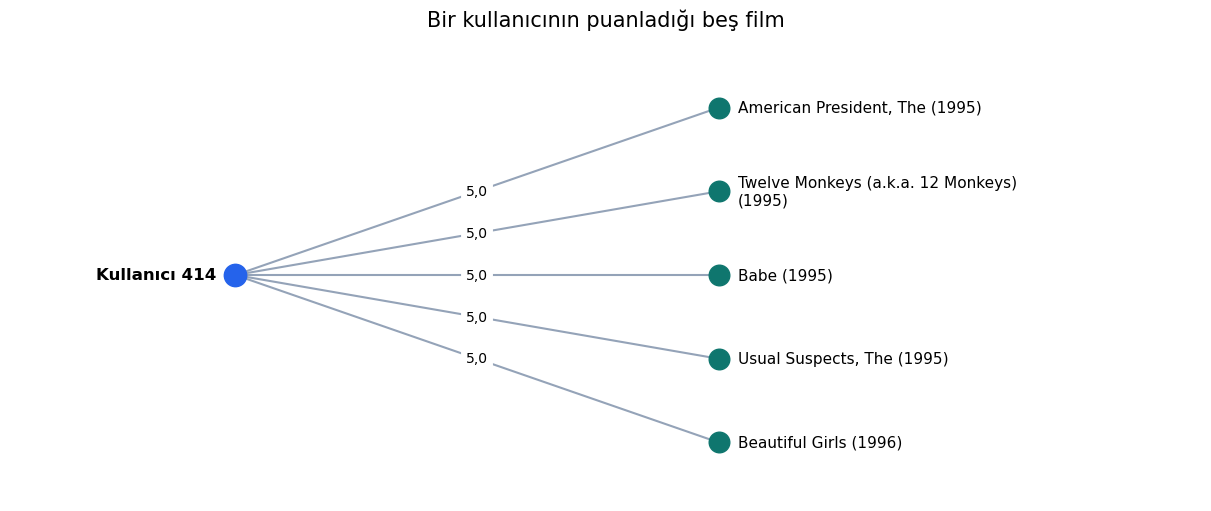

In [25]:
graph = nx.Graph()
user_nodes = [("user", uid) for uid in user_ids]
movie_nodes = [("movie", mid) for mid in movie_ids]
graph.add_nodes_from(user_nodes, bipartite=0)
graph.add_nodes_from(movie_nodes, bipartite=1)
graph.add_weighted_edges_from(
    (("user", row.userId), ("movie", row.movieId), row.rating)
    for row in train.itertuples(index=False)
)
assert graph.number_of_edges() == len(train)
assert nx.is_bipartite(graph)

nodes = user_nodes + movie_nodes
adjacency = nx.to_scipy_sparse_array(graph, nodelist=nodes, weight="weight", format="csr")
weights = csr_matrix(adjacency[:len(user_ids), len(user_ids):])
seen = [weights.getrow(i).indices for i in range(len(user_ids))]
n_users = len(user_nodes)
assert adjacency[:n_users, :n_users].nnz == 0
assert adjacency[n_users:, n_users:].nnz == 0
assert (adjacency[n_users:, :n_users] != weights.T).nnz == 0

degrees = pd.DataFrame({
    "Düğüm türü": ["Kullanıcı", "Film"],
    "Düğüm sayısı": [len(user_nodes), len(movie_nodes)],
    "Ortalama derece": [
        graph.number_of_edges() / len(user_nodes),
        graph.number_of_edges() / len(movie_nodes),
    ],
})
display(degrees)
likes = weights.copy()
likes.data = (likes.data >= LIKE).astype(float)
likes.eliminate_zeros()
popularity = np.asarray(likes.sum(axis=0)).ravel()

print("Düğüm:", graph.number_of_nodes(), "| Kenar:", graph.number_of_edges())
print("İki parçalı yoğunluk:", graph.number_of_edges() / (len(user_ids) * len(movie_ids)))

sample_user = max(user_nodes, key=graph.degree)
sample_movies = sorted(graph[sample_user], key=lambda node: (-graph[sample_user][node]["weight"], node[1]))[:5]
sample = graph.subgraph([sample_user, *sample_movies])

from textwrap import fill

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")

# Kullanıcı solda, filmler sağda ve eşit aralıklarla yer alır.
positions = {sample_user: (0, 0)}
positions.update({
    node: (3, (len(sample_movies) - 1) / 2 - i)
    for i, node in enumerate(sample_movies)
})

nx.draw_networkx_edges(
    sample, positions, ax=ax,
    edge_color="#94a3b8", width=1.5,
)
nx.draw_networkx_nodes(
    sample, positions, nodelist=[sample_user], ax=ax,
    node_color="#2563eb", node_size=260,
)
nx.draw_networkx_nodes(
    sample, positions, nodelist=sample_movies, ax=ax,
    node_color="#0f766e", node_size=220,
)

ax.annotate(
    f"Kullanıcı {sample_user[1]}",
    positions[sample_user],
    xytext=(-14, 0), textcoords="offset points",
    ha="right", va="center", fontsize=12, fontweight="bold",
)

for node in sample_movies:
    ax.annotate(
        fill(str(titles.loc[node[1]]), width=36),
        positions[node],
        xytext=(14, 0), textcoords="offset points",
        ha="left", va="center", fontsize=11,
    )

edge_labels = {
    (u, v): f"{data['weight']:.1f}".replace(".", ",")
    for u, v, data in sample.edges(data=True)
}
nx.draw_networkx_edge_labels(
    sample, positions, edge_labels=edge_labels,
    rotate=False, font_size=10, ax=ax,
)

ax.set_xlim(-1.4, 6.0)
ax.set_ylim(-len(sample_movies) / 2 - 0.2, len(sample_movies) / 2 + 0.2)
ax.set_title("Bir kullanıcının puanladığı beş film", fontsize=15, pad=16)
ax.set_axis_off()
plt.show()

## Graf Üzerinden Ulaşılabilen Filmler
Eğitim grafında birbirine doğrudan ya da başka düğümler üzerinden ulaşabilen kullanıcı ve film gruplarını belirledik. Bu gruplara bağlı bileşen adını verdik ve her grupta kaç kullanıcı ve film olduğunu hesapladık.

Kişiselleştirilmiş PageRank’i hedef kullanıcıdan başlattık. Bu yöntem grafın kenarlarını izlediği için yalnızca kullanıcıyla aynı gruptaki filmlere ulaşabildi. Diğer gruplardaki filmlerin PageRank puanı sıfır kaldı. Bu filmlerden biri ilk 10’a girdiyse, listeye sıfır puanlı adaylar arasındaki popülerlik sıralamasıyla girdi.

In [26]:
components = sorted(nx.connected_components(graph), key=len, reverse=True)
component_by_node = {
    node: number
    for number, component in enumerate(components, start=1)
    for node in component
}

component_summary = pd.DataFrame([
    {
        "Bileşen": number,
        "Düğüm": len(component),
        "Kullanıcı": sum(node[0] == "user" for node in component),
        "Film": sum(node[0] == "movie" for node in component),
    }
    for number, component in enumerate(components, start=1)
]).set_index("Bileşen")

print("Bağlı bileşen sayısı:", len(components))
display(component_summary.head(10))
display(
    (component_summary.iloc[0] / component_summary.sum())
    .rename("En büyük bileşenin payı")
    .to_frame()
    .style.format("{:.1%}")
)

Bağlı bileşen sayısı: 1


,Düğüm,Kullanıcı,Film
Bileşen,,,
1,8389,522,7867


,En büyük bileşenin payı
Düğüm,100.0%
Kullanıcı,100.0%
Film,100.0%


### Bağlı bileşen sonucunun kontrolü

Bir düğümden başlayarak genişlik öncelikli arama (BFS) yaptık. Ulaştığımız düğüm sayısı grafın toplam düğüm sayısına eşit çıktı. Böylece eğitim grafındaki 8.389 düğümün aynı bağlı bileşende yer aldığını doğruladık.

In [27]:
start_node = next(iter(graph))
reachable_count = 1 + sum(1 for _ in nx.bfs_edges(graph, start_node))

print("Bir düğümden ulaşılabilen düğüm sayısı:", reachable_count)
print("Graftaki toplam düğüm sayısı:", graph.number_of_nodes())

Bir düğümden ulaşılabilen düğüm sayısı: 8389
Graftaki toplam düğüm sayısı: 8389


## Film önerme yöntemleri

Her kullanıcı için aday filmlere üç farklı yöntemle puan verdik. Her yöntemde en yüksek puanı alan 10 filmi öneri listesine aldık.

1. Kullanıcı benzerliği. Hedef kullanıcıyla aynı filmleri beğenen kişileri belirledik. Bu kişilerin beğendiği aday filmlere puan verdik. Hedef kullanıcıya daha çok benzeyen bir kişinin beğenisi, filmin öneri puanına daha fazla katkı yaptı.
2. Film benzerliği. İki filmi de beğenen kullanıcılar üzerinden filmlerin benzerliğini hesapladık. Her aday filme, kullanıcının geçmişte beğendiği filmlerle olan benzerliklerini toplayarak puan verdik.
3. Kişiselleştirilmiş PageRank. Hedef kullanıcıdan başladık ve graf üzerinde puanlama bağlantılarını takip ettik. Her adımda %15 olasılıkla başlangıçtaki kullanıcıya döndük. Diğer adımlarda, daha yüksek puanlı bağlantılara daha fazla ağırlık verdik. Hesaplanan olasılıklar sabitlendiğinde, her film düğümünün olasılığını öneri puanı olarak kullandık.

İlk iki yöntemde, eğitim döneminde 5 üzerinden 4 veya daha yüksek puan verilen filmleri beğenilmiş saydık. Kullanıcı benzerliğini ortak beğenilen filmler, film benzerliğini ise iki filmi de beğenen kullanıcılar üzerinden hesapladık. Çok sayıda bağlantısı olan kullanıcı ve filmlerin sırf bu nedenle yüksek benzerlik puanı almasını sınırlamak için kosinüs benzerliği kullandık.

Karşılaştırma için aday filmleri eğitim döneminde aldıkları beğeni sayısına göre sıraladık. Böylece kişiselleştirilmiş önerilerin popüler film önerilerine göre ne kadar isabetli olduğunu ölçtük. Öneri puanları eşit olduğunda beğeni sayısına, o da eşitse film kimliğine göre sıraladık.

In [28]:
def inverse_positive(values):
    return np.divide(1.0, values, out=np.zeros_like(values, dtype=float), where=values > 0)


user_norm = np.sqrt(np.asarray(likes.sum(axis=1)).ravel())
movie_norm = np.sqrt(popularity)
user_vectors = (diags(inverse_positive(user_norm)) @ likes).tocsr()
movie_vectors = (likes @ diags(inverse_positive(movie_norm))).tocsr()
transition_t = (diags(inverse_positive(np.asarray(adjacency.sum(axis=1)).ravel())) @ adjacency).T.tocsr()


def user_scores(i):
    similarity = (user_vectors.getrow(i) @ user_vectors.T).toarray().ravel()
    similarity[i] = 0
    return np.asarray(likes.T @ similarity).ravel()


def film_scores(i):
    # Satır seçimiyle tüm film çiftleri için yoğun benzerlik matrisi oluşturmuyoruz.
    profile = likes.getrow(i)
    return (profile @ movie_vectors.T @ movie_vectors).toarray().ravel()


def pagerank_scores(i, alpha=0.85, tol=1e-8, max_iter=200):
    restart = np.zeros(len(nodes))
    restart[i] = 1.0
    state = restart.copy()
    for _ in range(max_iter):
        updated = alpha * (transition_t @ state) + (1 - alpha) * restart
        if np.abs(updated - state).sum() < tol:
            return updated[len(user_ids):]
        state = updated
    raise RuntimeError(f"PageRank yakınsamadı. Kullanıcı: {user_ids[i]}")


def top_k(scores, i):
    available = np.ones(len(movie_ids), dtype=bool)
    available[seen[i]] = False
    candidates = np.flatnonzero(available)
    order = np.lexsort((movie_ids[candidates], -popularity[candidates], -scores[candidates]))
    return candidates[order[:K]]


methods = {
    "Popülerlik": lambda i: popularity,
    "Kullanıcı benzerliği": user_scores,
    "Film benzerliği": film_scores,
    "Kişiselleştirilmiş PageRank": pagerank_scores,
}

# Küçük bir çapraz kontrol: seyrek matris hesabı ile NetworkX PageRank.
check_user = next(iter(relevant))
reference = nx.pagerank(
    graph, alpha=0.85, personalization={user_nodes[check_user]: 1.0},
    weight="weight", tol=1e-11, max_iter=200,
)
np.testing.assert_allclose(
    pagerank_scores(check_user), [reference[node] for node in movie_nodes], atol=1e-6
)

## Öneri yöntemlerinin değerlendirilmesi

İlk 10 öneriden kullanıcının test döneminde 
5 üzerinden 4 veya daha yüksek puan verdiği her filmi bir isabet olarak saydık. Yöntemleri iki ölçütle karşılaştırdık:

- **Precision@10:** Önerdiğimiz 10 filmin kaçının isabetli olduğunu ölçtük.
- **Recall@10:** Kullanıcının testte beğendiği ve öneri adayı olan filmlerin ne kadarını ilk 10’da yakaladığımızı ölçtük.

Örneğin bir kullanıcı testte 5 aday filmi beğendiyse ve bunların 3’ünü önerdiysek Precision@10 **3/10**, Recall@10 ise **3/5** oldu.

Yöntemlerin ortalama puanını hesaplarken eğitim döneminde film puanlamış ve test döneminde en az bir aday filmi beğenmiş kullanıcıları dahil ettik. Her kullanıcıya eşit ağırlık verdik. Eğitim döneminde puanlama geçmişi olmayan kullanıcılara popüler filmleri önerdik ve bu kullanıcıları performans ortalamasına dahil etmedik.

Öneri süresini ölçerken yalnızca filmlere puan verme ve listeyi sıralama işlemlerini hesaba kattık.

,Precision@10,Recall@10,Öneri süresi (sn)
Yöntem,,,
Popülerlik,0.0857,0.0449,0.0078
Kullanıcı benzerliği,0.1107,0.0547,0.0255
Film benzerliği,0.1000,0.0517,0.0299
Kişiselleştirilmiş PageRank,0.0857,0.0451,0.6557


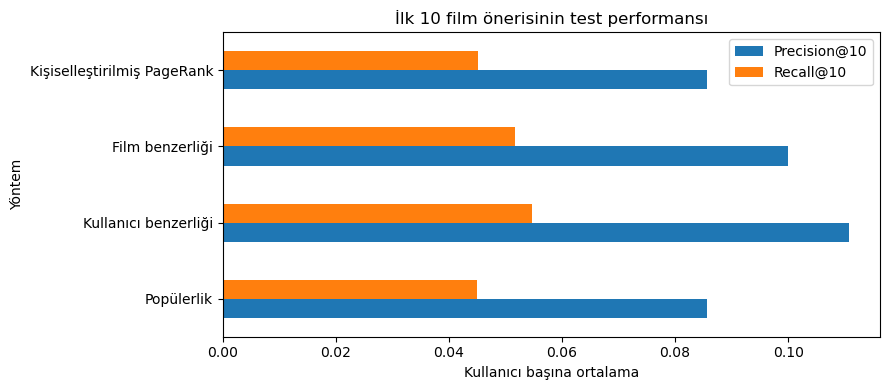

En yüksek graf yöntemi Recall@10: Kullanıcı benzerliği (0.0547)
Popülerlik baz çizgisine göre fark: +0.0097
Bu sıralama test sonuçlarının betimsel özetidir.


In [29]:
recommendations = {}
rows = []

for name, score_function in methods.items():
    start = perf_counter()
    ranked = {i: top_k(score_function(i), i) for i in relevant}
    elapsed = perf_counter() - start
    recommendations[name] = ranked

    precisions, recalls = [], []
    for i, top in ranked.items():
        assert not set(top).intersection(seen[i])
        hits = len(set(top).intersection(relevant[i]))
        precisions.append(hits / K)
        recalls.append(hits / len(relevant[i]))

    rows.append({
        "Yöntem": name,
        "Precision@10": np.mean(precisions),
        "Recall@10": np.mean(recalls),
        "Öneri süresi (sn)": elapsed,
    })

results = pd.DataFrame(rows).set_index("Yöntem")
display(results.round(4))
ax = results[["Precision@10", "Recall@10"]].plot.barh(figsize=(9, 4), rot=0)
ax.set_xlabel("Kullanıcı başına ortalama")
ax.set_title("İlk 10 film önerisinin test performansı")
plt.tight_layout()
plt.show()

baseline_recall = results.loc["Popülerlik", "Recall@10"]
comparison = results["Recall@10"].drop("Popülerlik")
best_method = comparison.idxmax()
print(f"En yüksek graf yöntemi Recall@10: {best_method} ({comparison.max():.4f})")
print(f"Popülerlik baz çizgisine göre fark: {comparison.max() - baseline_recall:+.4f}")
print("Bu sıralama test sonuçlarının betimsel özetidir.")

In [30]:
# Her kullanıcı için bütün yöntemlerin ilk 10 listesini dışa aktar.
export_rows = []
all_users = sorted(ratings.userId.unique())
cold_start_top = np.lexsort((movie_ids, -popularity))[:K]
for name, score_function in methods.items():
    for uid in all_users:
        i = user_index.get(uid)
        if i is None:
            top = cold_start_top
        elif i in recommendations[name]:
            top = recommendations[name][i]
        else:
            top = top_k(score_function(i), i)
        export_rows.extend(
            (uid, name, rank, movie_ids[j], titles.loc[movie_ids[j]], i is None)
            for rank, j in enumerate(top, start=1)
        )

recommendation_table = pd.DataFrame(
    export_rows,
    columns=["userId", "Yöntem", "Sıra", "movieId", "Film", "Eğitim geçmişi yok"]
)
recommendation_table.to_csv("ilk_10_film_onerileri.csv", index=False, encoding="utf-8-sig")
results.to_csv("yontem_karsilastirmasi.csv", encoding="utf-8-sig")

example_user = next(
    (i for i in relevant
     if len(recommendations["Film benzerliği"][i])
     and film_scores(i)[recommendations["Film benzerliği"][i][0]] > 0),
    check_user,
)
example_rows = []
for name, ranked in recommendations.items():
    for position, index in enumerate(ranked[example_user], start=1):
        example_rows.append({
            "Yöntem": name,
            "Sıra": position,
            "Film": titles.loc[movie_ids[index]],
            "Testte beğenilmiş": index in relevant[example_user],
        })

print("Örnek kullanıcı:", user_ids[example_user])
display(pd.DataFrame(example_rows).pivot(index="Sıra", columns="Yöntem", values="Film"))
example_table = pd.DataFrame(example_rows)
display(example_table.loc[example_table["Testte beğenilmiş"]])

# Film benzerliği önerisinde en büyük katkıyı yapan geçmiş filmi göster.
history = likes.getrow(example_user).indices
film_top = recommendations["Film benzerliği"][example_user]
if len(history) and len(film_top):
    index = film_top[0]
    contributions = (movie_vectors[:, history].T @ movie_vectors[:, [index]]).toarray().ravel()
    if contributions.max() > 0:
        source = history[contributions.argmax()]
        print(f'“{titles.loc[movie_ids[index]]}” için en güçlü geçmiş film: '
              f'“{titles.loc[movie_ids[source]]}” (kosinüs: {contributions.max():.3f})')

Örnek kullanıcı: 15


Yöntem,Film benzerliği,Kişiselleştirilmiş PageRank,Kullanıcı benzerliği,Popülerlik
Sıra,,,,
1,Confidence (2003),"Shawshank Redemption, The (1994)",Star Wars: Episode IV - A New Hope (1977),"Shawshank Redemption, The (1994)"
2,Bicentennial Man (1999),Forrest Gump (1994),"Matrix, The (1999)",Pulp Fiction (1994)
3,"Whole Nine Yards, The (2000)",Pulp Fiction (1994),Star Wars: Episode V - The Empire Strikes Back...,Forrest Gump (1994)
4,S.W.A.T. (2003),"Silence of the Lambs, The (1991)","Godfather, The (1972)","Silence of the Lambs, The (1991)"
5,"Patriot, The (2000)","Matrix, The (1999)",Raiders of the Lost Ark (Indiana Jones and the...,"Matrix, The (1999)"
6,Ferris Bueller's Day Off (1986),Star Wars: Episode IV - A New Hope (1977),Star Wars: Episode VI - Return of the Jedi (1983),Star Wars: Episode IV - A New Hope (1977)
7,Field of Dreams (1989),Braveheart (1995),Forrest Gump (1994),Braveheart (1995)
8,Risky Business (1983),Terminator 2: Judgment Day (1991),"Shawshank Redemption, The (1994)",Schindler's List (1993)
9,Die Hard 2 (1990),Jurassic Park (1993),Shrek (2001),"Usual Suspects, The (1995)"


,Yöntem,Sıra,Film,Testte beğenilmiş
0,Popülerlik,1,"Shawshank Redemption, The (1994)",True
1,Popülerlik,2,Pulp Fiction (1994),True
2,Popülerlik,3,Forrest Gump (1994),True
4,Popülerlik,5,"Matrix, The (1999)",True
5,Popülerlik,6,Star Wars: Episode IV - A New Hope (1977),True
7,Popülerlik,8,Schindler's List (1993),True
9,Popülerlik,10,Star Wars: Episode V - The Empire Strikes Back...,True
10,Kullanıcı benzerliği,1,Star Wars: Episode IV - A New Hope (1977),True
11,Kullanıcı benzerliği,2,"Matrix, The (1999)",True
12,Kullanıcı benzerliği,3,Star Wars: Episode V - The Empire Strikes Back...,True


“Confidence (2003)” için en güçlü geçmiş film: “Frequency (2000)” (kosinüs: 0.433)


## Bir film neden önerildi?

Örnek bir kullanıcı seçtik ve kişiselleştirilmiş PageRank’in bu kullanıcıdan başlayarak aday filmlerin ne kadarına ulaşabildiğini gösterdik.

Ardından film benzerliği yöntemiyle önerilen bir filmi inceledik. Örnek kullanıcının daha önce beğendiği bir filmi ve önerilen filmi beğenen başka bir kullanıcı bulduk. Bu bağlantıyı graf üzerinde çizdik:

**Örnek kullanıcı → Daha önce beğendiği film → İki filmi de beğenen kullanıcı → Önerilen film**

Bu yol, önerilen filmin kullanıcının geçmiş beğenileriyle nasıl bağlantılı olduğunu gösteren bir örnek.

Örnek kullanıcı: 15
Graf üzerinden erişilebilen aday film oranı: 100.0%


,Sıra,Film,PageRank puanı,Sıralama dayanağı
0,1,"Shawshank Redemption, The (1994)",0.001283,PageRank puanı
1,2,Forrest Gump (1994),0.001276,PageRank puanı
2,3,Pulp Fiction (1994),0.001200,PageRank puanı
3,4,"Silence of the Lambs, The (1991)",0.001102,PageRank puanı
4,5,"Matrix, The (1999)",0.001066,PageRank puanı
5,6,Star Wars: Episode IV - A New Hope (1977),0.001024,PageRank puanı
6,7,Braveheart (1995),0.000979,PageRank puanı
7,8,Terminator 2: Judgment Day (1991),0.000951,PageRank puanı
8,9,Jurassic Park (1993),0.000938,PageRank puanı
9,10,Schindler's List (1993),0.000923,PageRank puanı


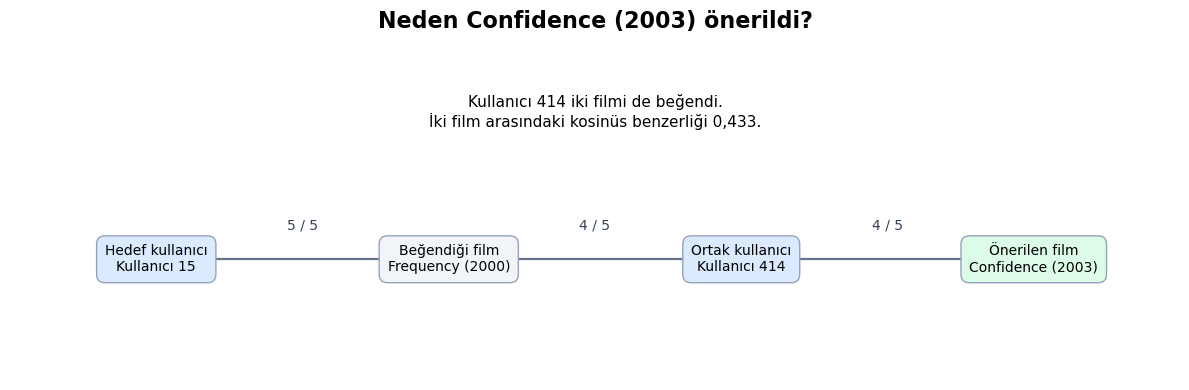

In [31]:
from textwrap import fill

i = example_user
candidate_mask = np.ones(len(movie_ids), dtype=bool)
candidate_mask[seen[i]] = False

user_component = component_by_node[user_nodes[i]]
reachable = np.array([
    component_by_node[node] == user_component
    for node in movie_nodes
])

scores = pagerank_scores(i)
assert np.allclose(scores[~reachable], 0)

print(f"Örnek kullanıcı: {user_ids[i]}")
print(
    "Graf üzerinden erişilebilen aday film oranı: "
    f"{reachable[candidate_mask].mean():.1%}"
)

ppr_top = recommendations["Kişiselleştirilmiş PageRank"][i]
display(pd.DataFrame({
    "Sıra": np.arange(1, len(ppr_top) + 1),
    "Film": titles.loc[movie_ids[ppr_top]].to_numpy(),
    "PageRank puanı": scores[ppr_top],
    "Sıralama dayanağı": np.where(
        scores[ppr_top] > 0,
        "PageRank puanı",
        "Popülerlik ile eşitlik çözümü",
    ),
}))

# Film benzerliği listesinden graf üzerinde açıklanabilecek ilk öneriyi seç.
history = likes.getrow(i).indices

for candidate in recommendations["Film benzerliği"][i]:
    similarities = (
        movie_vectors[:, history].T @ movie_vectors[:, [candidate]]
    ).toarray().ravel()

    if similarities.size == 0 or similarities.max() <= 0:
        continue

    prior = history[similarities.argmax()]
    prior_users = set(likes[:, [prior]].nonzero()[0])
    candidate_users = set(likes[:, [candidate]].nonzero()[0])
    shared_user = min((prior_users & candidate_users) - {i})

    path_nodes = [
        user_nodes[i],
        movie_nodes[prior],
        user_nodes[shared_user],
        movie_nodes[candidate],
    ]
    path_edges = list(zip(path_nodes, path_nodes[1:]))

    prior_title = str(titles.loc[movie_ids[prior]])
    recommended_title = str(titles.loc[movie_ids[candidate]])
    similarity_text = f"{similarities.max():.3f}".replace(".", ",")
    rating_text = [
        f"{graph.edges[edge]['weight']:g}".replace(".", ",")
        for edge in path_edges
    ]

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.set_xlim(-1, 7)
    ax.set_ylim(-0.9, 1.6)
    ax.set_axis_off()

    ax.set_title(
        fill(f"Neden {recommended_title} önerildi?", width=65),
        fontsize=16, fontweight="bold", pad=12,
    )
    ax.text(
        3, 1.1,
        f"Kullanıcı {user_ids[shared_user]} iki filmi de beğendi.\n"
        f"İki film arasındaki kosinüs benzerliği {similarity_text}.",
        ha="center", va="center", fontsize=11,
    )

    x_positions = [0, 2, 4, 6]
    node_labels = [
        f"Hedef kullanıcı\nKullanıcı {user_ids[i]}",
        f"Beğendiği film\n{fill(prior_title, width=19)}",
        f"Ortak kullanıcı\nKullanıcı {user_ids[shared_user]}",
        f"Önerilen film\n{fill(recommended_title, width=19)}",
    ]
    colors = ["#dbeafe", "#f1f5f9", "#dbeafe", "#dcfce7"]

    for left, right, rating in zip(x_positions, x_positions[1:], rating_text):
        ax.plot([left, right], [0, 0], color="#64748b", linewidth=1.6)
        ax.text(
            (left + right) / 2, 0.22, f"{rating} / 5",
            ha="center", fontsize=10, color="#334155",
        )

    for x, label, color in zip(x_positions, node_labels, colors):
        ax.text(
            x, 0, label, ha="center", va="center", fontsize=10,
            bbox={
                "boxstyle": "round,pad=0.6",
                "facecolor": color,
                "edgecolor": "#94a3b8",
            },
        )

    fig.tight_layout()
    plt.show()
    break
else:
    print("Bu kullanıcının ilk 10 film benzerliği önerisinde ortak beğeni yolu bulunamadı.")

## Bulguların yorumlanması

Kullanıcı benzerliği yöntemi, **%11,07 Precision@10** ve **%5,47 Recall@10** ile en yüksek sonuçları verdi. Popülerlik sıralamasında bu değerler sırasıyla **%8,57** ve **%4,49** oldu. Bu da ilk 10 öneride kullanıcı başına ortalama isabet sayısının yaklaşık **0,86’dan 1,11’e** çıktığını gösterdi.

Film benzerliği yöntemi de her iki ölçütte popülerlik sıralamasını geçti. Kişiselleştirilmiş PageRank ise Precision@10’da popülerlikle aynı sonucu verdi ve Recall@10’da ona çok yakın kaldı. Bu değerlendirmede kişiselleştirmenin katkısını en belirgin biçimde kullanıcı benzerliği yönteminde gördük.

Bu sonuçları tek bir eğitim–test ayrımında ve eğitim döneminde puanlanmış filmler üzerinden elde ettik. Kullanıcıların puanlamadığı filmler hakkındaki tercihlerini bilmediğimiz için isabetleri test dönemindeki bilinen beğenilere göre ölçtük.